# Intraday Crude Oil Data Exploration

This notebook explores the validated 15-minute WTI crude oil (CL) data produced by `src/prepare_intraday_data.py`, and compares it with the daily data where that helps strategy design. It reads only files in `data/processed/`. Run both preparation scripts first:

```bash
python src/prepare_daily_data.py --config config/prepare_daily.yaml
python -m src.prepare_intraday_data
```

The sample is the common window, 2025-01-02 to 2026-10-07 (443 trade dates). Times are Chicago time (CT), and each 15-minute bar is labeled by its end time, so the bar stamped 08:15 covers 08:00 to 08:15. Session and trading-window settings follow #4: a trade date runs from 17:00 CT on the prior day to 16:00 CT, and the intraday strategy trades only from 08:00 to 13:30 CT.

Sections: data quality, liquidity by time of day, volatility by time of day, where the daily move happens, return autocorrelation, gaps, roll effects, trading costs, and findings that affect strategy design.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(path for path in (Path("."), Path("..")) if (path / "data/processed").exists())
processed = root / "data/processed"
figures = root / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

bars = pd.read_parquet(processed / "cl_intraday_15m_continuous.parquet")
contracts = pd.read_parquet(processed / "cl_intraday_15m_contracts.parquet")
sessions = pd.read_parquet(processed / "cl_session_daily_continuous.parquet")
daily_utc = pd.read_parquet(processed / "cl_daily_continuous.parquet")
rolls = pd.read_csv(processed / "cl_intraday_roll_calendar.csv", parse_dates=["roll_date", "from_last_trade_date"])
coverage = pd.read_csv(processed / "cl_intraday_window_coverage.csv", parse_dates=["trade_date"])
summary = pd.read_csv(processed / "cl_intraday_quality_summary.csv")

# Chart style: shared with 02_daily_data_exploration.ipynb.
RAW, ADJUSTED, THIRD = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 1.2, "legend.frameon": False, "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
WINDOW_SHADE = "#efeee9"

# Price changes in USD/bbl along the back-adjusted held series. Signal prices remove roll gaps,
# so every change is a real move of one contract.
bars = bars.sort_values("timestamp").reset_index(drop=True)
bars["clock"] = bars["timestamp"].dt.strftime("%H:%M")
bars["move"] = bars["signal_close"].diff()
bars["first_bar_of_session"] = bars["trade_date"].ne(bars["trade_date"].shift())
bars.loc[bars.index[0], "move"] = np.nan

# Clock order of a session, from the 17:15 bar to the 16:00 bar.
session_clock = pd.date_range("2000-01-01 17:15", "2000-01-02 16:00", freq="15min").strftime("%H:%M")
window_clock = session_clock[(session_clock > "08:00") & (session_clock <= "13:30")]

print(f"Held-contract bars: {len(bars):,} over {bars['trade_date'].nunique()} trade dates "
      f"({bars['trade_date'].min().date()} to {bars['trade_date'].max().date()})")
print(f"Window bars:        {int(bars['in_trade_window'].sum()):,} ({len(window_clock)} per full trade date)")
print(f"Contract bars:      {len(contracts):,} across {contracts['contract_id'].nunique()} contracts")
print(f"Rolls:              {len(rolls)}")

Held-contract bars: 41,740 over 443 trade dates (2025-01-02 to 2026-10-07)
Window bars:        9,743 (22 per full trade date)
Contract bars:      456,260 across 71 contracts
Rolls:              21


## 1. Data-quality summary

Produced by the preparation script. Flags are reported, never silently removed.

In [2]:
with pd.option_context("display.max_colwidth", 140):
    display(summary)

,check,value,note
0,raw_rows,15196660,NaN
1,non_outright_rows_excluded,11554745,calendar spreads and other strategies
2,outright_rows,3641915,NaN
3,outright_missing_values,0,NaN
4,duplicate_instrument_timestamp_rows_removed,0,NaN
5,ts_monotonic_within_each_instrument,True,NaN
6,after_close_minutes_dropped,2,CLM6 2025-11-20 16:00:00-06:00 volume=1; CLQ6 2026-05-18 16:00:00-05:00 volume=1
7,folded_minutes,63723,holiday sessions folded into the next trade date
8,incomplete_trade_date_minutes_dropped,310,2026-10-08 (query ends 2026-10-08 00:00:00+00:00)
9,sample_trade_dates,443,2025-01-02 to 2026-10-07


## 2. Liquidity by time of day

Average share of the held contract's daily volume traded in each 15-minute bar. The shaded band is the 08:00 to 13:30 CT trading window from #4.

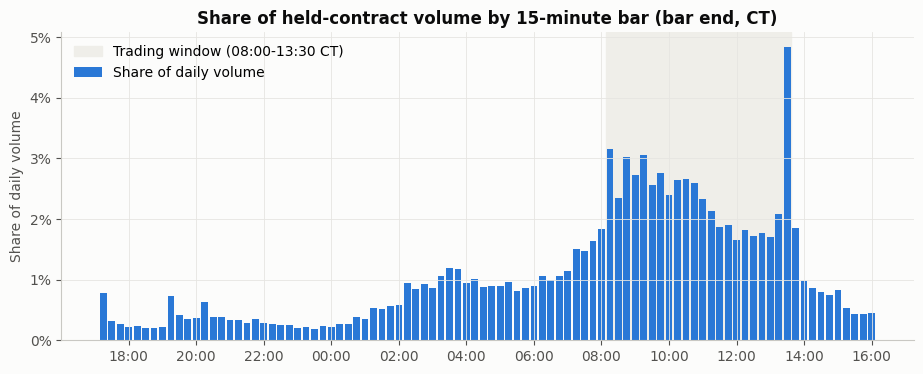

Trading window share of volume: 53.4% in 22 of 92 bars
Evening session (17:00-24:00 CT) share: 8.9%


,share of daily volume
13:30,4.8%
08:15,3.2%
09:15,3.1%
08:45,3.0%
09:45,2.8%
09:00,2.7%


In [3]:
volume_by_clock = bars.groupby("clock")["volume"].mean().reindex(session_clock)
volume_share = volume_by_clock / volume_by_clock.sum()

fig, ax = plt.subplots()
x = np.arange(len(session_clock))
in_window = np.isin(session_clock, window_clock)
ax.axvspan(x[in_window][0] - 0.5, x[in_window][-1] + 0.5, color=WINDOW_SHADE, zorder=0, label="Trading window (08:00-13:30 CT)")
ax.bar(x, volume_share.to_numpy(), width=0.8, color=RAW, label="Share of daily volume")
ticks = [i for i, clock in enumerate(session_clock) if clock.endswith(":00") and int(clock[:2]) % 2 == 0]
ax.set_xticks(ticks, [session_clock[i] for i in ticks])
ax.set_title("Share of held-contract volume by 15-minute bar (bar end, CT)")
ax.set_ylabel("Share of daily volume")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.legend(loc="upper left")
fig.savefig(figures / "intraday_volume_by_time.png")
plt.show()

window_share = bars.loc[bars["in_trade_window"], "volume"].sum() / bars["volume"].sum()
evening_share = volume_share[session_clock[session_clock >= "17:15"]].sum()
print(f"Trading window share of volume: {window_share:.1%} in {len(window_clock)} of {len(session_clock)} bars")
print(f"Evening session (17:00-24:00 CT) share: {evening_share:.1%}")
display(volume_share.sort_values(ascending=False).head(6).rename("share of daily volume").to_frame().style.format("{:.1%}"))

## 3. Volatility by time of day

Mean absolute 15-minute price change of the held contract, in USD/bbl. The first bar of each session (17:15 CT) is shown separately because its change spans the daily halt or a weekend.

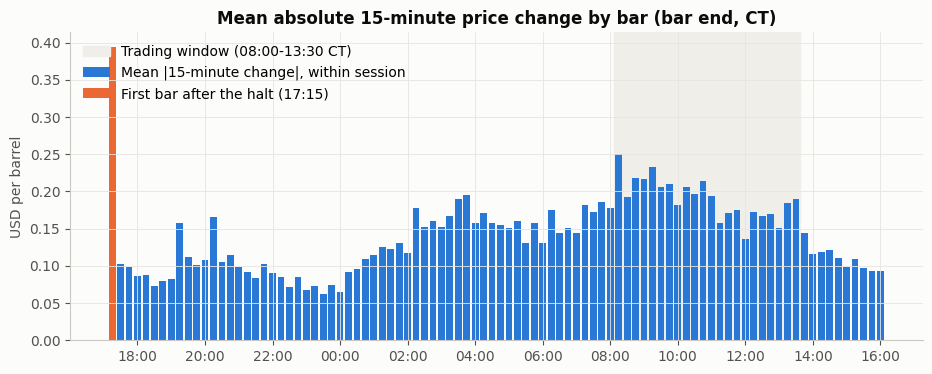

Window mean |change|: 0.193 USD/bbl; outside the window: 0.122


,mean |change| of the 09:45 bar (USD/bbl)
trade_date,
Monday,0.201
Tuesday,0.188
Wednesday,0.228
Thursday,0.218
Friday,0.218


In [4]:
within_session = bars[~bars["first_bar_of_session"]]
abs_move = within_session.groupby("clock")["move"].apply(lambda moves: moves.abs().mean()).reindex(session_clock)
reopen = bars.loc[bars["first_bar_of_session"], "move"].abs().mean()

fig, ax = plt.subplots()
ax.axvspan(x[in_window][0] - 0.5, x[in_window][-1] + 0.5, color=WINDOW_SHADE, zorder=0, label="Trading window (08:00-13:30 CT)")
ax.bar(x, abs_move.fillna(0).to_numpy(), width=0.8, color=RAW, label="Mean |15-minute change|, within session")
ax.bar([0], [reopen], width=0.8, color=ADJUSTED, label="First bar after the halt (17:15)")
ax.set_xticks(ticks, [session_clock[i] for i in ticks])
ax.set_title("Mean absolute 15-minute price change by bar (bar end, CT)")
ax.set_ylabel("USD per barrel")
ax.legend(loc="upper left")
fig.savefig(figures / "intraday_volatility_by_time.png")
plt.show()

# Scheduled releases: the EIA weekly petroleum report is at 09:30 CT on Wednesdays (bar ending 09:45).
eia = within_session[within_session["clock"].eq("09:45")]
by_weekday = eia.groupby(eia["trade_date"].dt.day_name())["move"].apply(lambda moves: moves.abs().mean())
by_weekday = by_weekday.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
print(f"Window mean |change|: {within_session.loc[within_session['in_trade_window'], 'move'].abs().mean():.3f} USD/bbl; "
      f"outside the window: {within_session.loc[~within_session['in_trade_window'], 'move'].abs().mean():.3f}")
display(by_weekday.rename("mean |change| of the 09:45 bar (USD/bbl)").to_frame().round(3))

## 4. Where the daily move happens

Each session's close-to-close change (16:00 CT to 16:00 CT, back-adjusted) is split into three parts:

- **overnight:** previous 16:00 close to the 08:00 bar close (includes the evening session and weekends);
- **window:** 08:00 to the 13:30 cutoff bar, the only part the intraday strategy can trade;
- **post-window:** 13:30 to the 16:00 close.

Each part's contribution to the variance of the daily change is cov(part, total) / var(total), so the contributions sum to 100%.

In [5]:
def price_at(group, clock):
    rows = group[group["clock"].le(clock) & group["timestamp"].dt.normalize().dt.tz_localize(None).eq(group["trade_date"])]
    return rows["signal_close"].iloc[-1] if len(rows) else np.nan

parts = []
for trade_date, group in bars.groupby("trade_date"):
    cutoff = group.loc[group["is_cutoff_bar"], "signal_close"]
    parts.append({
        "trade_date": trade_date,
        "at_0800": price_at(group, "08:00"),
        "at_cutoff": cutoff.iloc[0] if len(cutoff) else np.nan,
        "at_close": group["signal_close"].iloc[-1],
    })
parts = pd.DataFrame(parts).set_index("trade_date")
parts["overnight"] = parts["at_0800"] - parts["at_close"].shift()
parts["window"] = parts["at_cutoff"] - parts["at_0800"]
parts["post_window"] = parts["at_close"] - parts["at_cutoff"]
decomposition = parts[["overnight", "window", "post_window"]].dropna()
total = decomposition.sum(axis=1)

contribution = decomposition.apply(lambda part: part.cov(total) / total.var())
table = pd.DataFrame({
    "hours": [15, 5.5, 2.5],
    "std (USD/bbl)": decomposition.std(),
    "mean |change| (USD/bbl)": decomposition.abs().mean(),
    "share of daily variance": contribution,
})
display(table.style.format({"hours": "{:.1f}", "std (USD/bbl)": "{:.2f}", "mean |change| (USD/bbl)": "{:.2f}", "share of daily variance": "{:.0%}"}))
display(decomposition.corr().round(2))

,hours,std (USD/bbl),mean |change| (USD/bbl),share of daily variance
overnight,15.0,2.13,1.23,66%
window,5.5,1.34,0.90,27%
post_window,2.5,0.77,0.38,7%


,overnight,window,post_window
overnight,1.00,-0.13,-0.19
window,-0.13,1.00,0.16
post_window,-0.19,0.16,1.00


## 5. Return autocorrelation

A moving-average crossover profits when price changes are positively autocorrelated (trends persist). The chart shows the autocorrelation of 15-minute changes inside the trading window, with an approximate 95% band of ±2/√n, next to the autocorrelation of daily session changes over the same sample.

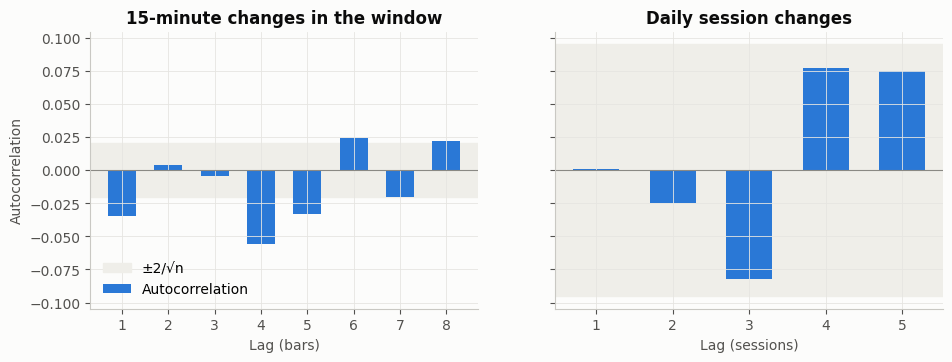

,"15-minute, window",daily session
1,-0.035,0.000
2,0.004,-0.025
3,-0.004,-0.082
4,-0.056,0.077
5,-0.033,0.075
6,0.024,NaN
7,-0.021,NaN
8,0.022,NaN


Observations: 9,743 window changes, 442 daily changes


In [6]:
window_moves = within_session.loc[within_session["in_trade_window"], ["trade_date", "move"]]

def autocorrelation(frame, lags):
    # Pair each change with the change `lag` bars earlier on the same trade date only.
    values = []
    for lag in lags:
        lagged = frame.groupby("trade_date")["move"].shift(lag)
        values.append(frame["move"].corr(lagged))
    return pd.Series(values, index=lags)

intraday_lags = range(1, 9)
intraday_acf = autocorrelation(window_moves, intraday_lags)
session_moves = sessions.sort_values("trade_date")["signal_close"].diff().dropna()
daily_lags = range(1, 6)
daily_acf = pd.Series([session_moves.autocorr(lag) for lag in daily_lags], index=daily_lags)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, acf, n, title in (
    (axes[0], intraday_acf, len(window_moves), "15-minute changes in the window"),
    (axes[1], daily_acf, len(session_moves), "Daily session changes"),
):
    band = 2 / np.sqrt(n)
    ax.axhspan(-band, band, color=WINDOW_SHADE, label="±2/√n")
    ax.bar(acf.index, acf.to_numpy(), width=0.6, color=RAW, label="Autocorrelation")
    ax.axhline(0, color="#8a8984", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Lag (bars)" if "15" in title else "Lag (sessions)")
axes[0].set_ylabel("Autocorrelation")
axes[0].legend(loc="lower left")
fig.savefig(figures / "intraday_autocorrelation.png")
plt.show()

display(pd.DataFrame({"15-minute, window": intraday_acf, "daily session": daily_acf}).round(3))
print(f"Observations: {len(window_moves):,} window changes, {len(session_moves)} daily changes")

## 6. Gaps

Three kinds of gap matter for the backtest: missing bars inside the trading window, thin bars (fewer than 15 one-minute bars), and the price jump between one session's 16:00 close and the next session's 17:00 reopen.

In [7]:
short_days = coverage[coverage["window_bars"].lt(coverage["expected_window_bars"])]
print(f"Trade dates with a full window: {int((coverage['window_bars'] == coverage['expected_window_bars']).sum())}/{len(coverage)}")
display(short_days)

thin = bars.assign(thin=bars["minutes"].lt(15)).groupby("in_trade_window")["thin"].mean()
print(f"Bars with fewer than 15 one-minute bars: {thin.get(True, 0):.1%} inside the window, {thin.get(False, 0):.1%} outside")

# Session close (16:00) to next reopen (17:00), relative to price. Weekends and holidays are included.
ordered = sessions.sort_values("trade_date").reset_index(drop=True)
reopen_gap = (ordered["open"] / ordered["close"].shift() - 1).where(ordered["instrument_id"].eq(ordered["instrument_id"].shift()))
weekend = ordered["trade_date"].diff().dt.days.gt(1)
utc = daily_utc[daily_utc["trade_date"].between(ordered["trade_date"].min(), ordered["trade_date"].max())].sort_values("trade_date").reset_index(drop=True)
utc_gap = (utc["open"] / utc["close"].shift() - 1).where(utc["instrument_id"].eq(utc["instrument_id"].shift()))
gap_table = pd.DataFrame({
    "session bars, weekdays": reopen_gap[~weekend].abs().describe(percentiles=[0.5, 0.99]),
    "session bars, after weekend/holiday": reopen_gap[weekend].abs().describe(percentiles=[0.5, 0.99]),
    "UTC daily bars (all)": utc_gap.abs().describe(percentiles=[0.5, 0.99]),
}).loc[["count", "mean", "50%", "99%", "max"]]
display(gap_table.style.format(lambda value: f"{value:.0f}" if value > 1 else f"{value:.3%}"))

Trade dates with a full window: 442/443


,trade_date,window_bars,window_volume,contract_id,expected_window_bars
246,2025-12-24,19,32470,CLG2026,22


Bars with fewer than 15 one-minute bars: 0.0% inside the window, 11.5% outside


,"session bars, weekdays","session bars, after weekend/holiday",UTC daily bars (all)
count,330,91,421
mean,0.109%,1.204%,0.269%
50%,0.047%,0.473%,0.015%
99%,1.057%,8.093%,5.267%
max,1.450%,11.458%,11.458%


## 7. Roll effects

Rolls happen 3 trade dates before expiry, at the session boundary, on the same dates as the daily pipeline. The chart shows how volume migrates from the expiring contract to the next one **inside the trading window**, by trade dates to expiry.

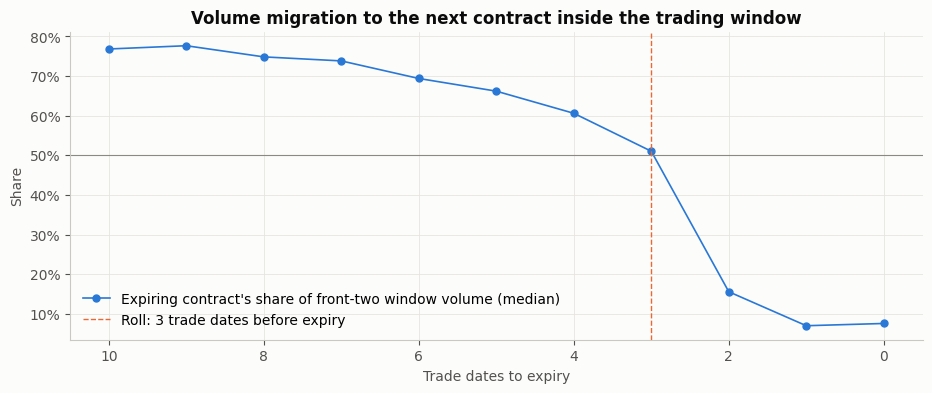

,median front share
sessions_to_expiry,
0,8%
1,7%
2,16%
3,51%
4,61%
5,66%
6,69%
7,74%
8,75%


Roll gaps (USD/bbl): mean |gap| 1.14, range -4.72 to -0.12


In [8]:
window_contracts = contracts[contracts["in_trade_window"]]
by_date = window_contracts.groupby(["trade_date", "contract_month"])["volume"].sum().reset_index()
front_two = []
for trade_date, group in by_date.groupby("trade_date"):
    listed = group.sort_values("contract_month")
    live = contracts.loc[contracts["trade_date"].eq(trade_date), ["contract_month", "sessions_to_expiry"]].drop_duplicates()
    live = live[live["sessions_to_expiry"].ge(0)].sort_values("contract_month")
    if len(live) < 2:
        continue
    front, second = live.iloc[0], live.iloc[1]
    volume = listed.set_index("contract_month")["volume"]
    front_two.append({
        "trade_date": trade_date,
        "sessions_to_expiry": int(front["sessions_to_expiry"]),
        "front_share": volume.get(front["contract_month"], 0) / (volume.get(front["contract_month"], 0) + volume.get(second["contract_month"], 0)),
    })
front_two = pd.DataFrame(front_two)
migration = front_two[front_two["sessions_to_expiry"].le(10)].groupby("sessions_to_expiry")["front_share"].median()

fig, ax = plt.subplots()
ax.plot(migration.index, migration.to_numpy(), color=RAW, marker="o", markersize=5, label="Expiring contract's share of front-two window volume (median)")
ax.axhline(0.5, color="#8a8984", linewidth=0.8)
ax.axvline(3, color=ADJUSTED, linestyle="--", linewidth=1, label="Roll: 3 trade dates before expiry")
ax.invert_xaxis()
ax.set_xlabel("Trade dates to expiry")
ax.set_ylabel("Share")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_title("Volume migration to the next contract inside the trading window")
ax.legend(loc="lower left")
fig.savefig(figures / "intraday_volume_migration.png")
plt.show()

display(migration.rename("median front share").to_frame().style.format("{:.0%}"))
print(f"Roll gaps (USD/bbl): mean |gap| {rolls['intraday_gap'].abs().mean():.2f}, "
      f"range {rolls['intraday_gap'].min():+.2f} to {rolls['intraday_gap'].max():+.2f}")

## 8. Trading costs relative to price moves

Using the cost settings in #4 ($2.50 commission plus 1 tick, $10, of slippage per contract per side, so $12.50 per side), this section estimates how much trading each horizon implies for the default and sensitivity moving-average windows. It counts trades only; it is **not** a backtest.

- **Intraday:** each full trade date has one entry at 08:00, one exit at the 13:30 cutoff, and two sides for every signal reversal in between. Signals use bars ending 08:00 to 13:15, because a signal at the cutoff bar is not executed.
- **Daily:** the position is always on, so each reversal costs two sides, and each roll costs two sides (close the old contract, open the new one). This uses the full 2010 to 2026 daily sample.

In [9]:
COST_PER_SIDE = 2.50 + 10.0          # USD per contract per side (#4)
CAPITAL = 100_000                    # USD (#4)
MULTIPLIER = 1_000                   # barrels per contract

def intraday_sides(fast, slow):
    signal = np.sign(bars["signal_close"].rolling(fast).mean() - bars["signal_close"].rolling(slow).mean())
    on_trade_date = bars["timestamp"].dt.normalize().dt.tz_localize(None).eq(bars["trade_date"])
    executable = bars["in_trade_window"] | (bars["clock"].eq("08:00") & on_trade_date)
    executable &= ~bars["is_cutoff_bar"]
    frame = pd.DataFrame({"trade_date": bars["trade_date"], "signal": signal})[executable]
    reversals = frame.groupby("trade_date")["signal"].apply(lambda s: int((s.diff().abs() == 2).sum()))
    return 2 + 2 * reversals

def daily_sides_per_year(fast, slow):
    held = daily_utc.sort_values("trade_date")
    signal = np.sign(held["signal_close"].rolling(fast).mean() - held["signal_close"].rolling(slow).mean())
    reversals = int((signal.diff().abs() == 2).sum())
    years = (held["trade_date"].iloc[-1] - held["trade_date"].iloc[slow]).days / 365.25
    return (2 * reversals + 2 * int(held["roll_flag"].sum())) / years, reversals / years

rows = []
for fast, slow in [(8, 32), (4, 32), (4, 64), (8, 64)]:
    sides = intraday_sides(fast, slow)
    per_year = sides.mean() * 252
    rows.append({"horizon": "15-minute", "fast/slow": f"{fast}/{slow}", "reversals per year": (sides.mean() - 2) / 2 * 252,
                 "sides per year": per_year, "cost per year (USD)": per_year * COST_PER_SIDE})
for fast, slow in [(20, 50), (10, 50), (10, 100), (20, 100)]:
    per_year, reversals = daily_sides_per_year(fast, slow)
    rows.append({"horizon": "daily", "fast/slow": f"{fast}/{slow}", "reversals per year": reversals,
                 "sides per year": per_year, "cost per year (USD)": per_year * COST_PER_SIDE})
costs = pd.DataFrame(rows)
costs["cost as % of capital"] = costs["cost per year (USD)"] / CAPITAL
display(costs.style.format({"reversals per year": "{:.1f}", "sides per year": "{:.0f}", "cost per year (USD)": "{:,.0f}", "cost as % of capital": "{:.1%}"}))

window_abs = within_session.loc[within_session["in_trade_window"], "move"].abs()
round_trip = 2 * COST_PER_SIDE / MULTIPLIER
print(f"Round-trip cost: {round_trip:.3f} USD/bbl; median |15-minute change| in the window: {window_abs.median():.3f} USD/bbl "
      f"(cost = {round_trip / window_abs.median():.0%} of a typical bar)")
print(f"Median |daily session change|: {session_moves.abs().median():.2f} USD/bbl")

,horizon,fast/slow,reversals per year,sides per year,cost per year (USD),cost as % of capital
0,15-minute,8/32,198.0,900,"11,249",11.2%
1,15-minute,4/32,257.7,1019,"12,742",12.7%
2,15-minute,4/64,186.6,877,"10,965",11.0%
3,15-minute,8/64,137.7,779,"9,742",9.7%
4,daily,20/50,5.3,35,437,0.4%
5,daily,10/50,6.8,38,474,0.5%
6,daily,10/100,4.1,33,411,0.4%
7,daily,20/100,3.8,32,401,0.4%


Round-trip cost: 0.025 USD/bbl; median |15-minute change| in the window: 0.120 USD/bbl (cost = 21% of a typical bar)
Median |daily session change|: 1.03 USD/bbl


## 9. Session bars vs. UTC daily bars

The common-window daily horizon uses session bars built from the 1-minute data, while the full-sample daily backtest uses Databento's UTC-day bars. This checks how closely the two daily series agree over the overlap.

In [10]:
overlap = sessions[["trade_date", "contract_id", "close", "signal_close"]].merge(
    daily_utc[["trade_date", "contract_id", "close", "signal_close"]], on="trade_date", suffixes=("_session", "_utc")
)
same_contract = overlap["contract_id_session"].eq(overlap["contract_id_utc"]).mean()
changes = overlap[["signal_close_session", "signal_close_utc"]].diff().dropna()
print(f"Trade dates in both series: {len(overlap)}; same held contract: {same_contract:.1%}")
print(f"Correlation of daily changes (session vs. UTC bars): {changes.corr().iloc[0, 1]:.3f}")
print(f"Median |close difference|: {(overlap['close_session'] - overlap['close_utc']).abs().median():.2f} USD/bbl")

Trade dates in both series: 443; same held contract: 100.0%
Correlation of daily changes (session vs. UTC bars): 0.884
Median |close difference|: 0.07 USD/bbl


## 10. Findings that affect strategy design

These findings come from the outputs above (common window 2025-01-02 to 2026-10-07, 443 trade dates, 41,740 held-contract 15-minute bars, 21 rolls).

1. **The 15-minute data is clean enough for an intraday backtest.** No missing values, duplicates, OHLC inconsistencies, or zero-volume bars. Every bar inside the trading window is built from a full 15 minutes of data, and 442 of 443 trade dates have all 22 window bars (2025-12-24 closed early, so its cutoff bar is at 12:45 CT). All 125 outliers in the held series are matched by the next listed month, so they are market moves, not bad prints.
2. **The trading window is where the liquidity is.** It holds 53% of the held contract's volume in 22 of 92 bars, and the 13:30 CT cutoff bar (the settlement window) is the single most liquid bar of the day (4.8% of volume). Flattening at the cutoff bar is therefore realistic, and the 1-tick slippage assumption is reasonable inside the window.
3. **Most of the daily move happens outside the window.** The overnight period (16:00 CT to 08:00 CT) accounts for about 66% of the variance of the daily change, the window for 27%, and 13:30 to 16:00 for 7%. A strategy that is flat overnight can capture at most the window's share, while the daily strategy is exposed to all of it. This is the main structural difference between the two horizons and should frame the comparison in the report.
4. **15-minute changes show slight mean reversion, not momentum.** Inside the window, the lag-1 autocorrelation is −0.035 and lag 4 is −0.056, both outside the ±0.020 band. Daily session changes show no significant autocorrelation in this short sample (band ±0.095). A moving-average crossover needs persistent trends, so the intraday version starts with a small headwind.
5. **Costs are the binding constraint for the intraday horizon.** A round trip costs 0.025 USD/bbl, about 21% of a typical 15-minute move in the window. With daily entries and exits plus around 140 to 260 reversals a year, the intraday windows in the #4 grid imply roughly 10% to 13% of capital per year in costs, against about 0.4% for the daily windows. The intraday strategy must earn a gross edge above that level to break even, so the cost sensitivity in #4 (0.5×, 1×, 2×) is essential for this horizon.
6. **Rolls behave the same way intraday.** Inside the window, the expiring contract still carries a median 51% of front-two volume 3 trade dates before expiry and 16% at 2, consistent with the daily data and the roll rule in #4. Roll gaps in this sample are all negative (backwardation, −4.72 to −0.12 USD/bbl), so the adjusted series must be used for signals. Because intraday positions are flat at every session end, the intraday strategy never pays a roll trade.
7. **Weekend gaps dominate the reopen gap.** The gap from the 16:00 CT close to the 17:00 CT reopen is small on weekdays (median 0.05%) but much larger after weekends and holidays (median 0.47%, 99th percentile 8.1%). The intraday strategy avoids this risk; the daily strategy holds through it.
8. **Use session bars for the common-window daily comparison.** Session bars and Databento's UTC-day bars hold the same contract on every date, but their daily changes have a correlation of only 0.88, because UTC bars close at midnight UTC (two to three hours after 16:00 CT) and include the start of the next session. Session bars align both horizons on the same 16:00 CT close.
9. **The 15-minute horizon is viable as a data question, but marginal as a strategy question.** Liquidity, coverage, and data quality all support a 15-minute backtest. The weak autocorrelation and high cost intensity mean a weak or negative net result is a likely and legitimate outcome, which the README explicitly allows.